In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

In [2]:
DATASET_PATH = Path("../data/WELFake_Dataset.csv")

df = pd.read_csv(DATASET_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (72134, 4)


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  72134 non-null  int64
 1   title       71576 non-null  str  
 2   text        72095 non-null  str  
 3   label       72134 non-null  int64
dtypes: int64(2), str(2)
memory usage: 235.0 MB


In [4]:
df.describe(include='all')

,Unnamed: 0,title,text,label
count,72134.000000,71576,72095,72134.000000
unique,NaN,62347,62718,NaN
top,NaN,Factbox: Trump fills top jobs for his administ...,,NaN
freq,NaN,14,738,NaN
mean,36066.500000,NaN,NaN,0.514404
std,20823.436496,NaN,NaN,0.499796
min,0.000000,NaN,NaN,0.000000
25%,18033.250000,NaN,NaN,0.000000
50%,36066.500000,NaN,NaN,1.000000
75%,54099.750000,NaN,NaN,1.000000


In [5]:
missing =df.isnull().sum()
missing


Unnamed: 0      0
title         558
text           39
label           0
dtype: int64

<Axes: title={'center': 'Missing Values per Column'}>

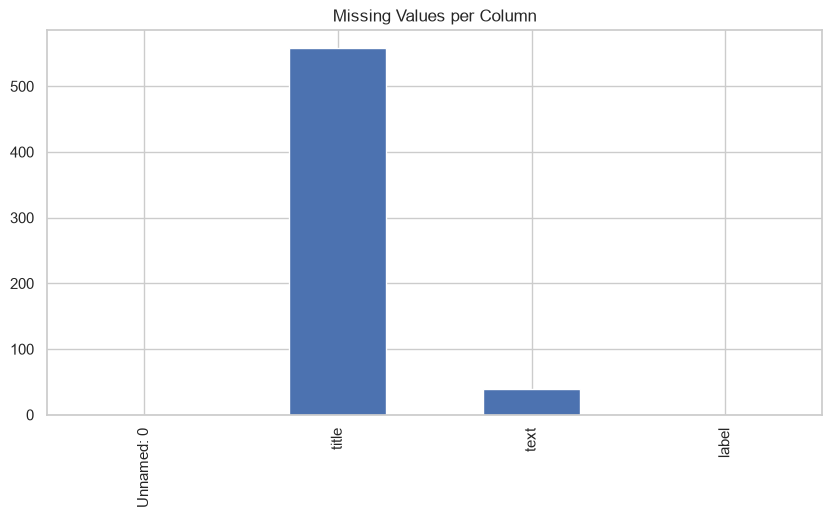

In [6]:
missing.plot(kind='bar', figsize=(10, 5), title='Missing Values per Column')

label
1    37106
0    35028
Name: count, dtype: int64


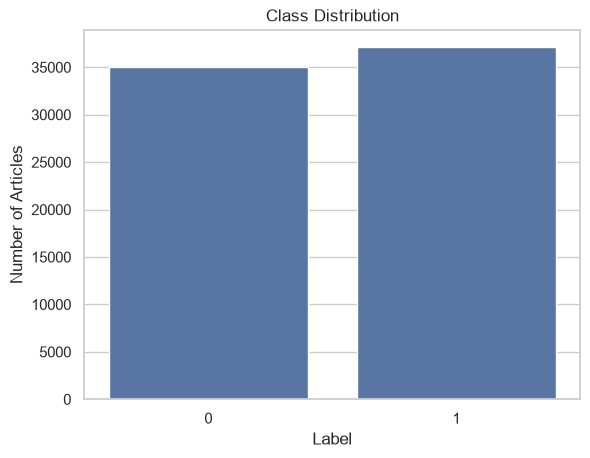

In [7]:
print(df["label"].value_counts())

sns.countplot(data=df, x="label")
plt.title("Class Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Articles")
plt.show()


In [8]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate titles:", df["title"].duplicated().sum())

print("Duplicate texts:", df["text"].duplicated().sum())

Duplicate rows: 0
Duplicate titles: 9786
Duplicate texts: 9415


In [9]:

print("Empty titles:", (df["title"].fillna("").str.strip() == "").sum())

print("Empty texts:", (df["text"].fillna("").str.strip() == "").sum())

print("Duplicate titles:", df["title"].dropna().duplicated().sum())

print("Duplicate texts:", df["text"].dropna().duplicated().sum())

print("\nLabel mapping candidates:")
print(df.groupby("label")[["title", "text"]].first())


Empty titles: 558
Empty texts: 783
Duplicate titles: 9229
Duplicate texts: 9377

Label mapping candidates:
                                                   title  \
label                                                      
0      Bobby Jindal, raised Hindu, uses story of Chri...   
1      LAW ENFORCEMENT ON HIGH ALERT Following Threat...   

                                                    text  
label                                                     
0      A dozen politically active pastors came here f...  
1      No comment is expected from Barack Obama Membe...  


In [10]:
for label in sorted(df["label"].unique()):
    print(f"\n========== LABEL {label} ==========")

    sample = df.loc[df["label"] == label, ["title", "text"]].head(5)

    for _, row in sample.iterrows():
        print("\nTitle:", row["title"])
        print("Text:", str(row["text"])[:300])


========== LABEL 0 ==========

Title: Bobby Jindal, raised Hindu, uses story of Christian conversion to woo evangelicals for potential 2016 bid
Text: A dozen politically active pastors came here for a private dinner Friday night to hear a conversion story unique in the context of presidential politics: how Louisiana Gov. Bobby Jindal traveled from Hinduism to Protestant Christianity and, ultimately, became what he calls an “evangelical Catholic.”

Title: May Brexit offer would hurt, cost EU citizens - EU parliament
Text: BRUSSELS (Reuters) - British Prime Minister Theresa May s offer of  settled status  for EU residents is flawed and will leave them with fewer rights after Brexit, the European Parliament s Brexit coordinator said on Tuesday. A family of five could face a bill of 360 pounds to acquire the new status,

Title: Schumer calls on Trump to appoint official to oversee Puerto Rico relief
Text: WASHINGTON (Reuters) - Charles Schumer, the top Democrat in the U.S. Senate, called 

In [11]:
text_data = df.dropna(subset=["text"]).copy()

text_data["normalized_text"] = (
    text_data["text"]
    .astype("string")
    .str.lower()
    .str.strip()
)

conflicting_texts = (
    text_data.groupby("normalized_text")["label"]
    .nunique()
)

conflicting_texts = conflicting_texts[
    conflicting_texts > 1
]

print("Conflicting unique texts:", len(conflicting_texts))

Conflicting unique texts: 1


In [12]:
import os

os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"


import re
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

DATA_PATH = Path("data/WELFake_Dataset.csv")

print("Setup complete!")

Setup complete!


In [13]:
DATA_PATH = Path("../data/WELFake_Dataset.csv")

df = pd.read_csv(DATA_PATH)

In [14]:
conflicting_texts = (
    text_data.groupby("normalized_text")
    .filter(lambda x: x["label"].nunique() > 1)
)

print("Conflicting rows:", len(conflicting_texts))

display(
    conflicting_texts[
        ["label", "title", "text"]
    ].head(10)
)

Conflicting rows: 744


,label,title,text
7,1,HOUSE INTEL CHAIR On Trump-Russia Fake Story: ...,
106,1,MARKETWATCH LEFTIST: MSM’s “Blatant” Anti Trum...,
325,1,Ohio State University Student Says Terrorist A...,
364,1,JULIAN ASSANGE REVEALS John Podesta’s Hilariou...,
512,1,OBAMA’S LIST OF 21 MEDAL OF FREEDOM Recipients...,
514,1,HILARIOUS TRUMP CHRISTMAS VIDEO: “It’s The Mos...,
555,1,AWESOME! JEWISH DEMOCRAT LEADER Hits Back At H...,
670,1,WOW! LEGAL HISPANIC AMERICAN IMMIGRANT Unloads...,
674,1,OBAMA DANCES At Last-Ever White House Gig To D...,
676,1,TREY GOWDY ON SPYING ON AMERICAN CITIZENS…Like...,


In [15]:
conflict_groups = (
    text_data.groupby("normalized_text")["label"]
    .nunique()
)

conflict_groups = conflict_groups[conflict_groups > 1]

print("Conflicting unique articles:", len(conflict_groups))
print("Total rows involved:", len(conflicting_texts))

Conflicting unique articles: 1
Total rows involved: 744


In [16]:
display(
    conflicting_texts[
        ["label", "title", "text"]
    ].head(10)
)

,label,title,text
7,1,HOUSE INTEL CHAIR On Trump-Russia Fake Story: ...,
106,1,MARKETWATCH LEFTIST: MSM’s “Blatant” Anti Trum...,
325,1,Ohio State University Student Says Terrorist A...,
364,1,JULIAN ASSANGE REVEALS John Podesta’s Hilariou...,
512,1,OBAMA’S LIST OF 21 MEDAL OF FREEDOM Recipients...,
514,1,HILARIOUS TRUMP CHRISTMAS VIDEO: “It’s The Mos...,
555,1,AWESOME! JEWISH DEMOCRAT LEADER Hits Back At H...,
670,1,WOW! LEGAL HISPANIC AMERICAN IMMIGRANT Unloads...,
674,1,OBAMA DANCES At Last-Ever White House Gig To D...,
676,1,TREY GOWDY ON SPYING ON AMERICAN CITIZENS…Like...,


In [17]:
print(
    conflicting_texts["label"]
    .value_counts()
)

label
1    743
0      1
Name: count, dtype: int64


In [18]:
text_data = df.loc[
    df["text"].notna()
    & df["text"].astype("string").str.strip().ne(""),
    ["label", "title", "text"]
].copy()

text_data["normalized_text"] = (
    text_data["text"]
    .astype("string")
    .str.lower()
    .str.strip()
)

conflicting_texts = (
    text_data.groupby("normalized_text")
    .filter(lambda x: x["label"].nunique() > 1)
)

print("Conflicting rows:", len(conflicting_texts))

Conflicting rows: 0


In [19]:
empty_text = (
    df["text"].isna()
    | df["text"].astype("string").str.strip().eq("")
)

print("Missing/empty article bodies:", empty_text.sum())
print("Total rows:", len(df))

Missing/empty article bodies: 783
Total rows: 72134


In [20]:
title_missing = (
    df["title"].isna()
    | df["title"].astype("string").str.strip().eq("")
)

text_missing = (
    df["text"].isna()
    | df["text"].astype("string").str.strip().eq("")
)

print("Missing titles:", title_missing.sum())
print("Missing article bodies:", text_missing.sum())

print("Both missing:", (title_missing & text_missing).sum())
print("Only title available:", (title_missing.eq(False) & text_missing).sum())
print("Only article body available:", (title_missing & text_missing.eq(False)).sum())

Missing titles: 558
Missing article bodies: 783
Both missing: 0
Only title available: 783
Only article body available: 558


In [21]:
print(df["label"].value_counts(dropna=False))

print("\nLabel percentages:")
print(df["label"].value_counts(normalize=True, dropna=False) * 100)

label
1    37106
0    35028
Name: count, dtype: int64

Label percentages:
label
1    51.440375
0    48.559625
Name: proportion, dtype: float64


In [22]:
df_clean = df[["label", "title", "text"]].copy()

df_clean["title"] = df_clean["title"].fillna("").astype(str).str.strip()
df_clean["text"] = df_clean["text"].fillna("").astype(str).str.strip()

df_clean["combined_text"] = (
    df_clean["title"] + " " + df_clean["text"]
).str.strip()

df_clean = df_clean[
    df_clean["combined_text"].ne("")
].copy()

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Missing combined text:", df_clean["combined_text"].eq("").sum())

display(df_clean[["label", "combined_text"]].head())

Original rows: 72134
Cleaned rows: 72134
Missing combined text: 0


,label,combined_text
0,1,LAW ENFORCEMENT ON HIGH ALERT Following Threat...
1,1,Did they post their votes for Hillary already?
2,1,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...
3,0,"Bobby Jindal, raised Hindu, uses story of Chri..."
4,1,SATAN 2: Russia unvelis an image of its terrif...


In [23]:
for label in [0, 1]:
    print(f"\nLABEL: {label}")
    display(
        df_clean[df_clean["label"] == label]
        [["title", "text"]]
        .head(3)
    )


LABEL: 0


,title,text
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...
11,"May Brexit offer would hurt, cost EU citizens ...",BRUSSELS (Reuters) - British Prime Minister Th...
12,Schumer calls on Trump to appoint official to ...,"WASHINGTON (Reuters) - Charles Schumer, the to..."



LABEL: 1


,title,text
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...
1,,Did they post their votes for Hillary already?
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last n..."


In [24]:
print("Duplicate combined texts:",
      df_clean["combined_text"].duplicated().sum())

print("Duplicate complete rows:",
      df_clean.duplicated().sum())

Duplicate combined texts: 8458
Duplicate complete rows: 8458


In [25]:
duplicate_groups = (
    df_clean.groupby("combined_text")["label"]
    .nunique()
)

conflicting_groups = duplicate_groups[duplicate_groups > 1]

print("Conflicting duplicate groups:", len(conflicting_groups))

Conflicting duplicate groups: 0


In [26]:
duplicate_mask = df_clean["combined_text"].duplicated(keep=False)

display(
    df_clean.loc[
        duplicate_mask,
        ["label", "combined_text"]
    ].sort_values("combined_text").head(10)
)


,label,combined_text
34585,1,"""Top Five Clinton Donors Are Jewish"" - How Ant..."
40330,1,"""Top Five Clinton Donors Are Jewish"" - How Ant..."
15085,1,#2816: Clinton Pride’s 8(a) Pig Farm Bridge – ...
22321,1,#2816: Clinton Pride’s 8(a) Pig Farm Bridge – ...
1946,1,#AnyoneButHillary: NEW POLL Shows Bernie Suppo...
22104,1,#AnyoneButHillary: NEW POLL Shows Bernie Suppo...
44258,1,#Austin: Fights Break Out Between Police and S...
44689,1,#Austin: Fights Break Out Between Police and S...
1109,1,#BREAKING: SECOND Assassination Attempt On Tru...
63047,1,#BREAKING: SECOND Assassination Attempt On Tru...


In [27]:
df_clean = df_clean.drop_duplicates(
    subset=["combined_text"],
    keep="first"
).reset_index(drop=True)

print("Rows after removing duplicates:", len(df_clean))
print("Remaining duplicates:", df_clean["combined_text"].duplicated().sum())
print("Label distribution:")
print(df_clean["label"].value_counts())

Rows after removing duplicates: 63676
Remaining duplicates: 0
Label distribution:
label
0    34790
1    28886
Name: count, dtype: int64


In [28]:
for label in [0, 1]:
    print(f"\nLABEL: {label}")
    display(
        df_clean[df_clean["label"] == label]
        [["combined_text"]]
        .sample(5, random_state=42)
    )


LABEL: 0


,combined_text
16797,"Ugandan MPs get $8,000 each for work on extend..."
38294,"With Trump victory, blunt U.S. general gets se..."
56143,"Russia, Syria armies step up attacks on Damasc..."
20745,Trying to move on from the U.S. election? Tune...
32185,Minnesota Governor Dayton released from hospit...



LABEL: 1


,combined_text
18180,High Ranking Russian Official Confirms Being I...
39128,BREAKING : AP (Finally) Calls Arizona For Trum...
2253,Hillary Turns Her Back on Standing Rock Sioux:...
3024,President-elect Donald Trump eyes Ovala Office...
18867,Colbert Lays A Catholic Smack Down On Trump Ov...


In [29]:
from sklearn.model_selection import train_test_split

X = df_clean["combined_text"]
y = df_clean["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training samples: 50940
Testing samples: 12736

Training distribution:
label
0    54.636828
1    45.363172
Name: proportion, dtype: float64

Testing distribution:
label
0    54.632538
1    45.367462
Name: proportion, dtype: float64


In [30]:
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nLabel mapping candidates:")
print(df_clean.groupby("label")["combined_text"].apply(
    lambda x: x.sample(min(3, len(x)), random_state=42).tolist()
))

Train shape: (50940,)
Test shape: (12736,)

Label mapping candidates:
label
0    [Ugandan MPs get $8,000 each for work on exten...
1    [High Ranking Russian Official Confirms Being ...
Name: combined_text, dtype: object


In [31]:
for label in [0, 1]:
    print(f"\nLABEL {label}")

    samples = df[df["label"] == label].sample(
        10, random_state=42
    )

    for _, row in samples.iterrows():
        print("Title:", row["title"])
        print("Text:", str(row["text"])[:300])
        print("-" * 80)


LABEL 0
Title: Two People Die after Eating Raw-Milk Cheese Made in New York State - The New York Times
Text: Two people have died following an outbreak of listeria linked to a popular artisanal raw milk cheese made in upstate New York, the authorities said this week. The deaths occurred in Vermont and Connecticut, local officials said. Four other people in New York and Florida reported feeling sick after e
--------------------------------------------------------------------------------
Title: DUP blames Sinn Fein for Northern Ireland talks collapse
Text: BELFAST (Reuters) - A senior member of Northern Ireland s Democratic Unionist Party on Wednesday blamed rivals Sinn Fein for the collapse of talks on forming a power-sharing government and suggested the DUP would not compromise on the key issue of the Irish language.  In the first public statement f
--------------------------------------------------------------------------------
Title: Exclusive: Former top Brazil prosecutor says succ

In [32]:
for label in [0, 1]:
    subset = df[df["label"] == label]

    print(f"\nLABEL {label}")
    print("Rows:", len(subset))

    print("\nSample titles:")
    for title in subset["title"].dropna().sample(
        15, random_state=42
    ):
        print("-", title)


LABEL 0
Rows: 35028

Sample titles:
- Two People Die after Eating Raw-Milk Cheese Made in New York State - The New York Times
- DUP blames Sinn Fein for Northern Ireland talks collapse
- Exclusive: Former top Brazil prosecutor says successor, police chief slowing graft probes
- U.S. intelligence chief says Russia involvement in 2016 election unprecedented
- Macri's coalition poised to win key Argentina midterm vote: opinion polls
- ¿Qué bolá? Obama jokes with Cuban humorist in video
- Bolton on Susan Rice Scandal: Obama Needs to Be Asked What He Knew and When He Knew It
- Germany not mulling sanctions against U.S. after climate pact withdrawal
- NBC News Releases First Promo for ’Sunday Night with Megyn Kelly’ (Video)
- Japan's struggling opposition Democrats pick ex-foreign minister Maehara as leader
- Applications Open For the Yiannopoulos Privilege Grant - Breitbart
- Thousands of Tunisians protest against Trump's Jerusalem decision
- The teachable moment of Saudi Arabia’s economic

In [33]:
df_clean["label"] = df_clean["label"].map({
    0: 1,
    1: 0
})

print(df_clean["label"].value_counts())

label
1    34790
0    28886
Name: count, dtype: int64


In [34]:
from sklearn.model_selection import train_test_split

X = df_clean["combined_text"]
y = df_clean["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nTrain labels:")
print(y_train.value_counts())

print("\nTest labels:")
print(y_test.value_counts())

Train: (50940,)
Test: (12736,)

Train labels:
label
1    27832
0    23108
Name: count, dtype: int64

Test labels:
label
1    6958
0    5778
Name: count, dtype: int64


In [35]:
import numpy as np
import gc

from sklearn.feature_extraction.text import HashingVectorizer
from scipy.sparse import vstack

vectorizer = HashingVectorizer(
    n_features=2**16,
    ngram_range=(1, 2),
    stop_words="english",
    alternate_sign=False,
    norm="l2",
    dtype=np.float32
)

In [36]:
batch_size = 500
train_batches = []

for start in range(0, len(X_train), batch_size):
    batch = X_train.iloc[start:start + batch_size]
    train_batches.append(vectorizer.transform(batch))

X_train_tfidf = vstack(train_batches, format="csr")

del train_batches
gc.collect()

print(X_train_tfidf.shape)

(50940, 65536)


In [37]:
test_batches = []

for start in range(0, len(X_test), batch_size):
    batch = X_test.iloc[start:start + batch_size]
    test_batches.append(vectorizer.transform(batch))

X_test_tfidf = vstack(test_batches, format="csr")

del test_batches
gc.collect()

print(X_test_tfidf.shape)

(12736, 65536)


In [38]:
print("Train shape:", X_train_tfidf.shape)
print("Test shape:", X_test_tfidf.shape)

print("Train matrix type:", type(X_train_tfidf))
print("Train matrix memory (MB):",
      (X_train_tfidf.data.nbytes
       + X_train_tfidf.indices.nbytes
       + X_train_tfidf.indptr.nbytes) / (1024**2))

Train shape: (50940, 65536)
Test shape: (12736, 65536)
Train matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Train matrix memory (MB): 182.55410385131836


In [39]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, nb_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    nb_predictions,
    target_names=["Fake", "Real"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nb_predictions))

Accuracy: 0.8719378140703518

Classification Report:
              precision    recall  f1-score   support

        Fake       0.86      0.86      0.86      5778
        Real       0.88      0.88      0.88      6958

    accuracy                           0.87     12736
   macro avg       0.87      0.87      0.87     12736
weighted avg       0.87      0.87      0.87     12736


Confusion Matrix:
[[4954  824]
 [ 807 6151]]


In [40]:
results = {}

results["Multinomial Naive Bayes"] = {
    "accuracy": accuracy_score(y_test, nb_predictions),
    "macro_f1": 0.87
}

print(results)

{'Multinomial Naive Bayes': {'accuracy': 0.8719378140703518, 'macro_f1': 0.87}}


In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

lr_model = LogisticRegression(
    C=1.0,
    max_iter=1000,
    solver="liblinear",
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, lr_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Fake", "Real"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_predictions))

Accuracy: 0.9468435929648241

Classification Report:
              precision    recall  f1-score   support

        Fake       0.94      0.94      0.94      5778
        Real       0.95      0.95      0.95      6958

    accuracy                           0.95     12736
   macro avg       0.95      0.95      0.95     12736
weighted avg       0.95      0.95      0.95     12736


Confusion Matrix:
[[5448  330]
 [ 347 6611]]


In [42]:
from sklearn.metrics import f1_score

results["Multinomial Naive Bayes"] = {
    "accuracy": accuracy_score(y_test, nb_predictions),
    "macro_f1": f1_score(y_test, nb_predictions, average="macro")
}

print(results)

{'Multinomial Naive Bayes': {'accuracy': 0.8719378140703518, 'macro_f1': 0.8707965230480684}}


In [43]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    C=1.0,
    max_iter=1000,
    solver="liblinear",
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, lr_predictions))

print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Fake", "Real"]
))

Accuracy: 0.9468435929648241
              precision    recall  f1-score   support

        Fake       0.94      0.94      0.94      5778
        Real       0.95      0.95      0.95      6958

    accuracy                           0.95     12736
   macro avg       0.95      0.95      0.95     12736
weighted avg       0.95      0.95      0.95     12736



In [44]:
results["Logistic Regression"] = {
    "accuracy": accuracy_score(y_test, lr_predictions),
    "macro_f1": f1_score(y_test, lr_predictions, average="macro")
}

print(results)

{'Multinomial Naive Bayes': {'accuracy': 0.8719378140703518, 'macro_f1': 0.8707965230480684}, 'Logistic Regression': {'accuracy': 0.9468435929648241, 'macro_f1': 0.9463966155908179}}


In [45]:
from sklearn.metrics import f1_score

results["Logistic Regression"] = {
    "accuracy": accuracy_score(y_test, lr_predictions),
    "macro_f1": f1_score(
        y_test, lr_predictions, average="macro"
    )
}

results["Multinomial Naive Bayes"] = {
    "accuracy": accuracy_score(y_test, nb_predictions),
    "macro_f1": f1_score(
        y_test, nb_predictions, average="macro"
    )
}

print(results)

{'Multinomial Naive Bayes': {'accuracy': 0.8719378140703518, 'macro_f1': 0.8707965230480684}, 'Logistic Regression': {'accuracy': 0.9468435929648241, 'macro_f1': 0.9463966155908179}}


In [46]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=30,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    n_jobs=1,
    random_state=42
)

rf_model.fit(X_train_tfidf, y_train)

rf_predictions = rf_model.predict(X_test_tfidf)

In [47]:
print("Accuracy:", accuracy_score(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=["Fake", "Real"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

Accuracy: 0.9161432160804021

Classification Report:
              precision    recall  f1-score   support

        Fake       0.93      0.88      0.90      5778
        Real       0.90      0.95      0.93      6958

    accuracy                           0.92     12736
   macro avg       0.92      0.91      0.91     12736
weighted avg       0.92      0.92      0.92     12736


Confusion Matrix:
[[5069  709]
 [ 359 6599]]


In [48]:
from sklearn.metrics import f1_score

results["Random Forest"] = {
    "accuracy": accuracy_score(y_test, rf_predictions),
    "macro_f1": f1_score(
        y_test, rf_predictions, average="macro"
    )
}

import pandas as pd

comparison = pd.DataFrame(results).T
comparison = comparison.sort_values(
    by="accuracy", ascending=False
)

print(comparison)

                         accuracy  macro_f1
Logistic Regression      0.946844  0.946397
Random Forest            0.916143  0.914915
Multinomial Naive Bayes  0.871938  0.870797


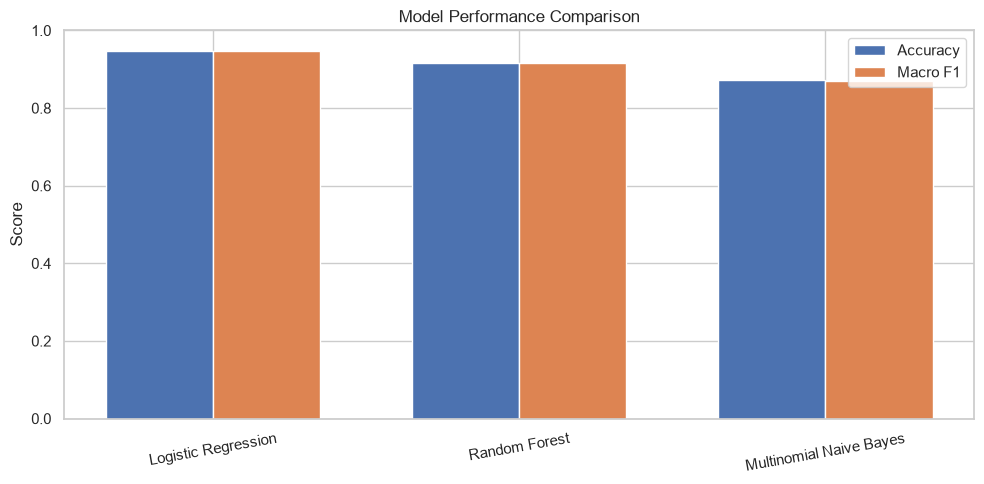

In [49]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

models = comparison.index.tolist()

plt.figure(figsize=(10, 5))

x = np.arange(len(models))
width = 0.35

plt.bar(x - width/2, comparison["accuracy"], width, label="Accuracy")
plt.bar(x + width/2, comparison["macro_f1"], width, label="Macro F1")

plt.xticks(x, models, rotation=10)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Model Performance Comparison")
plt.legend()
plt.tight_layout()
plt.show()

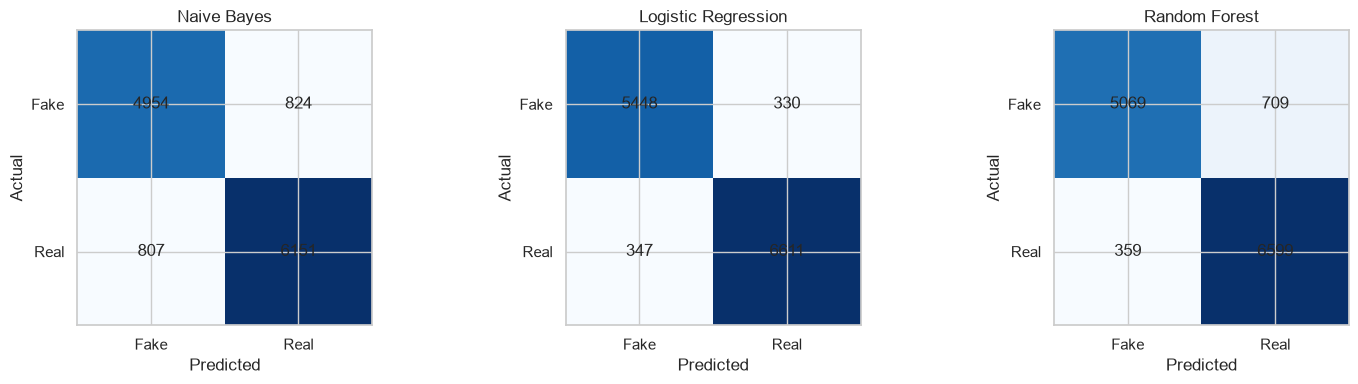

In [50]:
predictions = {
    "Naive Bayes": nb_predictions,
    "Logistic Regression": lr_predictions,
    "Random Forest": rf_predictions
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)

    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0, 1], ["Fake", "Real"])
    ax.set_yticks([0, 1], ["Fake", "Real"])

    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()